# Práctica 4 - Detección de Vehículos y Matrículas
## Asignatura: Visión por Computador

### Autoría: Grupo 33
- **Álvaro García Suárez** ([GitHub: @agsuarezz](https://github.com/agsuarezz))
- **Marcos González Gómez** ([GitHub: @mgz00](https://github.com/mgz00))

---

## Descripción del Proyecto y Objetivos

En esta práctica se desarrolla un sistema integral de visión artificial sobre secuencias de vídeo orientado a la **monitorización inteligente del tráfico** y la **localización de vehículos y matrículas**.

El trabajo cubre el **100% de los requisitos obligatorios** de la entrega y **todos los puntos extras (+1.75 puntos)**:

1. **Detección y seguimiento persistente (Tracking)** de vehículos y personas mediante **YOLO11** y **BoT-SORT**, garantizando persistencia de identificadores (`track_id`) y registro de trayectorias.
2. **Entrenamiento de un detector de matrículas personalizado**: procesado del dataset real (2.386 pares de imágenes y anotaciones, con más de 5.200 matrículas), entrenamiento en GPU RTX 4070 SUPER y análisis detallado de curvas de aprendizaje (`loss`, `mAP50`, `confusion_matrix`).
3. **Localización de matrículas y asignación espacial**: vinculación directa entre la matrícula detectada y el vehículo correspondiente en cada fotograma.
4. **Conteo global y desglose por categorías**: conteo en tiempo real de peatones, coches, motos, autobuses y camiones.
5. **Extras implementados (+1.75 puntos)**:
   - **Extra 1 (+0.25p)**: Conteo del **flujo de coches hacia la cámara y hacia el fondo** en `C0142`.
   - **Extra 2 (+1.00p)**: Comparativa empírica exhaustiva entre **YOLO** y **RT-DETR** (arquitectura basada en Transformers).
   - **Extra 3 (+0.25p)**: Detector de matrículas mediante **técnicas clásicas de contornos y morfología matemática** en OpenCV.
   - **Extra 4 (+0.25p)**: Módulo de **anonimización de privacidad** (desenfoque gaussiano de personas y matrículas).
6. **Exportación estandarizada**: generación del archivo CSV oficial con las 15 columnas requeridas y vídeo anotado con HUD en tiempo real.

### Ejecutar desde cero

Abre el notebook desde la carpeta `P4` con un kernel de Python 3.12. Conserva `P4b` junto a `P4` para consultar los resultados de OCR. Coloca `C0142.MP4` dentro de `P4` para procesar el vídeo. La comparativa de RT-DETR requiere tener Git instalado y acceso a Internet para descargar el código y los pesos. El primer uso de OCR también descarga sus modelos.

Ejecuta la celda de instalación y después la de imports. Si ya tenías el notebook en ejecución antes de instalar, reinicia el kernel y continúa desde los imports.


In [ ]:
# Paso 0. Instalar las dependencias en el Python del kernel.
import re
import shutil
import subprocess
import sys

# En Windows, instala la versión CUDA si el controlador NVIDIA admite CUDA 13 o posterior.
nvidia_smi = shutil.which("nvidia-smi")
use_cuda = False
if sys.platform == "win32" and nvidia_smi:
    gpu_info = subprocess.run([nvidia_smi], capture_output=True, text=True)
    cuda_version = re.search(r"CUDA (?:UMD )?Version:\s+(\d+)\.", gpu_info.stdout)
    use_cuda = gpu_info.returncode == 0 and cuda_version is not None and int(cuda_version[1]) >= 13

pip = [sys.executable, "-m", "pip", "install"]
if use_cuda:
    subprocess.run(
        [*pip, "--index-url", "https://download.pytorch.org/whl/cu130",
         "torch==2.14.1+cu130", "torchvision==0.29.1+cu130"],
        check=True,
    )

subprocess.run(
    [*pip, "torch", "torchvision", "ultralytics", "opencv-python", "numpy",
     "pandas", "matplotlib", "Pillow", "lap", "PyYAML", "faster-coco-eval>=1.6.6",
     "tensorboard", "scipy", "packaging", "pycocotools", "scikit-image",
     "python-bidi", "shapely", "pyclipper", "ninja", "rich", "tqdm",
     "onnxruntime", "transformers>=4.56,<5"],
    check=True,
)
# Los dos motores usan cv2. Instalamos sus otras dependencias arriba para
# conservar OpenCV sin que opencv-python-headless sobrescriba los mismos archivos.
subprocess.run(
    [*pip, "--no-deps", "easyocr==1.7.2", "fast-plate-ocr==1.1.0"], check=True
)
print("Dependencias listas. Si ya habías importado librerías, reinicia el kernel antes de continuar.")


In [ ]:
# Importación de librerías esenciales
import os
import sys
import time
import glob
import json
import random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from collections import defaultdict
import torch

SRC_DIR = os.path.abspath("src")
if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)
from ultralytics import YOLO

# Verificación de aceleración hardware (GPU)
print("=== VERIFICACIÓN DEL ENTORNO DE EJECUCIÓN ===")
device = "cuda:0" if torch.cuda.is_available() else "cpu"
print(f"Dispositivo activo: {device}")
if torch.cuda.is_available():
    print(f"GPU detectada: {torch.cuda.get_device_name(0)}")
    print(f"Versión de PyTorch: {torch.__version__}")
    print(f"Memoria VRAM disponible: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
else:
    print("CUDA no disponible. Ejecución en CPU.")


---
## Pasos 1 y 2. Cargar el detector de matrículas preentrenado

El notebook utiliza `best_matriculas.pt`, incluido en P4. El README describe cómo se preparó el dataset y cómo se entrenó el modelo.


In [ ]:
from pathlib import Path

plate_weights = Path(SRC_DIR).parent / "best_matriculas.pt"
if not plate_weights.is_file():
    raise FileNotFoundError(f"No se encontraron los pesos entrenados: {plate_weights}")
plate_model = YOLO(str(plate_weights))
print(f"Detector de matrículas cargado desde {plate_weights.name}.")


---
## Paso 3: Comparativa YOLO vs RT-DETR (Extra 2: +1.00p)

Como se describe en el apartado 4.5 del README, recientes cambios en la licencia de Ultralytics (AGPL-3.0) han motivado la búsqueda de alternativas comerciales abiertas como **RT-DETR** (publicado por Baidu bajo licencia **Apache 2.0** y basado en arquitectura **Transformers**).

En este apartado evaluamos de forma empírica ambos modelos en nuestra GPU **RTX 4070 SUPER**:
- **Velocidad de inferencia (FPS y latencia media en ms)**
- **Número de detecciones y umbrales de confianza**
- **Arquitectura subyacente y consideraciones de despliegue**


In [ ]:
# Descargar el código de RT-DETR v2 en la carpeta P4 (ejecutar antes de la comparativa).
import subprocess
import sys
from pathlib import Path

p4_dir = Path(SRC_DIR).parent
rtdetr_dir = p4_dir / "RT-DETR"
rtdetr_core = rtdetr_dir / "rtdetrv2_pytorch" / "src" / "core" / "__init__.py"
if not rtdetr_core.is_file():
    subprocess.run(
        ["git", "clone", "--depth", "1", "https://github.com/lyuwenyu/RT-DETR.git", str(rtdetr_dir)],
        check=True,
    )
print("Código de RT-DETR listo. La comparativa descargará los pesos si faltan.")


In [ ]:
# Benchmark comparativo entre YOLO11 y RT-DETR v2-S sobre test.jpg
from load_rtdetr import load_rtdetr
from PIL import Image

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
test_img_path = "test.jpg"
bgr_test = cv2.imread(test_img_path)
h, w = bgr_test.shape[:2]

# 1. Medición de YOLO11n
yolo_gen = YOLO("yolo11n.pt")
# Warmup
for _ in range(5):
    _ = yolo_gen(bgr_test, device=DEVICE, verbose=False)

t0 = time.time()
n_iters = 30
for _ in range(n_iters):
    res_yolo = yolo_gen(bgr_test, device=DEVICE, verbose=False)
yolo_time = (time.time() - t0) / n_iters
yolo_fps = 1.0 / yolo_time
yolo_dets = len(res_yolo[0].boxes)

# 2. Medición de RT-DETR v2-S
rtdetr_model, rtdetr_post = load_rtdetr(family="v2", size="s", device=DEVICE)
im_pil = Image.fromarray(cv2.cvtColor(bgr_test, cv2.COLOR_BGR2RGB)).resize((640, 640), Image.BILINEAR)
x_rt = torch.from_numpy(np.array(im_pil)).permute(2, 0, 1).float().div(255)[None].to(DEVICE)

# Warmup
with torch.no_grad():
    for _ in range(5):
        _ = rtdetr_post(rtdetr_model(x_rt), torch.tensor([[w, h]], device=DEVICE))

t0 = time.time()
with torch.no_grad():
    for _ in range(n_iters):
        labels_rt, boxes_rt, scores_rt = rtdetr_post(rtdetr_model(x_rt), torch.tensor([[w, h]], device=DEVICE))
rtdetr_time = (time.time() - t0) / n_iters
rtdetr_fps = 1.0 / rtdetr_time

scores_np = scores_rt[0].cpu().numpy()
rtdetr_dets = int(np.sum(scores_np >= 0.4))

# Tabla resumen
df_comp = pd.DataFrame({
    "Modelo": ["YOLO11 Nano (Ultralytics)", "RT-DETR v2-S (Baidu)"],
    "Arquitectura": ["CNN con Bloques C3k2 + C2PSA", "Vision Transformer (Backbone ResNet18-vd)"],
    "Licencia": ["AGPL-3.0 (Restricción comercial)", "Apache 2.0 (Comercial permisiva)"],
    "Latencia (ms/img)": [f"{yolo_time*1000:.2f} ms", f"{rtdetr_time*1000:.2f} ms"],
    "Velocidad (FPS)": [f"{yolo_fps:.1f} FPS", f"{rtdetr_fps:.1f} FPS"],
    "Detecciones (conf >= 0.4)": [yolo_dets, rtdetr_dets]
})

print("=== TABLA COMPARATIVA YOLO vs RT-DETR ===")
display(df_comp)


---
## Paso 4: Detección de Matrículas mediante Contornos y Morfología (Extra 3: +0.25p)

Como alternativa a los modelos de deep learning, se implementa una técnica clásica basada en visión por computador tradicional:
1. **Restricción espacial**: se analiza la mitad inferior del vehículo detectado.
2. **Filtrado bilateral**: eliminación de ruido conservando bordes nítidos.
3. **Morfología Black-Hat**: resalta regiones oscuras sobre fondos claros (caracteres sobre placa).
4. **Gradiente horizontal Sobel X**: acentúa las transiciones verticales típicas de los números y letras.
5. **Binarización de Otsu y clausura**: unión de los caracteres en una masa rectangular coherente.
6. **Filtrado geométrico**: relación de aspecto ($2.2 \le AR \le 6.0$) y área relativa respecto al coche.


In [ ]:
# Demostración paso a paso del detector clásico por contornos
from pathlib import Path
from traffic_pipeline import detect_plate_contours

# Cargar un coche de muestra
p4_dir = Path(SRC_DIR).parent
sample_path = p4_dir / "dataset" / "test" / "images" / "00002.jpg"
sample_car = cv2.imread(str(sample_path)) if sample_path.is_file() else None
if sample_car is None:
    fallback_path = p4_dir / "test.jpg"
    street_image = cv2.imread(str(fallback_path))
    if street_image is None:
        raise FileNotFoundError(f"No se pudo leer {sample_path} ni {fallback_path}")
    # Recorte del frontal de la furgoneta verde en la imagen de prueba.
    sample_car = street_image[378:425, 745:844]

# Aplicar el detector clásico
plate_box = detect_plate_contours(sample_car)

# Visualización
img_display = sample_car.copy()
if plate_box:
    x1, y1, x2, y2 = plate_box
    cv2.rectangle(img_display, (x1, y1), (x2, y2), (0, 255, 0), 3)
    cv2.putText(img_display, "Matricula (Contorno)", (x1, y1 - 8),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(img_display, cv2.COLOR_BGR2RGB))
plt.title(f"Detección Clásica por Contornos y Morfología | Box: {plate_box}", fontsize=13, fontweight="bold")
plt.axis("off")
plt.show()


---
## Paso 5: Módulos Extras: Flujo Direccional (Extra 1) y Anonimización (Extra 4)

- **Flujo Direccional (+0.25p)**: se sigue el centro inferior de cada caja de coche. Cada `track_id` suma una vez al cruzar la línea transversal de la calzada en su sentido.
  - **Hacia la cámara**: cruza hacia abajo por los carriles de la izquierda.
  - **Hacia el fondo**: cruza hacia arriba por los carriles de la derecha.
  - El HUD y el resumen muestran ambos recuentos y el sentido con más tráfico.
- **Anonimización (+0.25p)**: desenfoque gaussiano dinámico aplicado automáticamente sobre todas las personas y las matrículas de los vehículos antes de la renderización del vídeo para proteger la privacidad.


In [ ]:
# Demostración del Módulo de Anonimización de Privacidad
from traffic_pipeline import apply_anonymization

demo_frame = cv2.imread("test.jpg")
# Simulamos recuadros a anonimizar
res_y = yolo_gen(demo_frame, classes=[0], conf=0.4, verbose=False)
boxes_persons = res_y[0].boxes.xyxy.cpu().numpy().astype(int).tolist()

anon_frame = apply_anonymization(demo_frame, boxes_persons)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
axes[0].imshow(cv2.cvtColor(demo_frame, cv2.COLOR_BGR2RGB))
axes[0].set_title("Fotograma Original", fontsize=13, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(anon_frame, cv2.COLOR_BGR2RGB))
axes[1].set_title("Fotograma Anonimizado (Blur de Privacidad en Personas)", fontsize=13, fontweight="bold")
axes[1].axis("off")

plt.tight_layout()
plt.show()


---
## Paso 6: Procesamiento Integral del Vídeo de Tráfico (`C0142.MP4`)

Ejecutamos el pipeline completo combinando todos los componentes:
- Detección y seguimiento persistente con **BoT-SORT** y filtrado de vehículos estacionados (`VehicleMotionFilter`)
- Localización con `best_matriculas.pt` y registro único por ID de vehículo, con recuadro de matrícula persistente en el vídeo
- Reconocimiento OCR en cascada híbrida (`PlateOCR`: `fast-plate-ocr` → `EasyOCR` → `SmolVLM-Instruct`) con consenso multiframe
- Conteo acumulado por clases y monitorización de flujo direccional
- Renderizado de HUD en tiempo real con recuadros de seguimiento y matrícula leída
- Generación del archivo CSV oficial con las 15 columnas (incluyendo `texto_matricula`) y vídeo anotado.

El vídeo usa EasyOCR por defecto. Cambia `ocr_mode` a `"hybrid"` si quieres ejecutar la cascada completa con Fast Plate OCR, EasyOCR y SmolVLM. SmolVLM descarga sus pesos en el primer uso (aprox. 4,5 GB).


In [ ]:
# Ejecutar el pipeline sobre el vídeo oficial guardando resultados en results/.
from pathlib import Path
from traffic_pipeline import TrafficAnalyzer

video_input = Path("C0142.MP4")
if not video_input.is_file():
    raise FileNotFoundError(f"No se encontró el vídeo de entrada: {video_input}")

video_output = f"results/resultado_{video_input.stem}_tracking.mp4"
csv_output = f"results/resultado_{video_input.stem}_detecciones.csv"

analyzer = TrafficAnalyzer(
    general_model_path="yolo11m.pt",
    plate_model_path=str(plate_weights),
    conf_thres=0.10,
    imgsz=1280,
    device=device,
    ocr_mode="easyocr"
)
metricas = analyzer.process_video(
    video_path=str(video_input),
    output_video_path=video_output,
    output_csv_path=csv_output,
    anonymize=False,
    use_contour_plates=False,
    only_moving=True,
    motion_min_span=30.0,
    display=False
)

---
## Paso 7: Inspección del Archivo CSV Oficial y Fotogramas Resultantes

Se comprueba que el fichero CSV cumple estrictamente con el formato estipulado por los profesores:
`fotograma, tipo_objeto, confianza, identificador_tracking, x1, y1, x2, y2, matrícula_en_su_caso, confianza, mx1,my1,mx2,my2, texto_matricula`


In [ ]:
# Comprobar que cada ID tiene como máximo un registro de matrícula.
df_resultado = pd.read_csv(csv_output)
matriculas = df_resultado.loc[df_resultado["matrícula_en_su_caso"] == "Si"]
assert matriculas["identificador_tracking"].is_unique
print(f"Total de registros generados: {len(df_resultado)}")
print(f"Matrículas registradas: {len(matriculas)}")
print(f"Columnas registradas ({len(df_resultado.columns)} columnas):")
print(list(df_resultado.columns))
display(df_resultado.head(10))

In [ ]:
# Inspección visual de fotogramas clave del vídeo procesado.
cap_out = cv2.VideoCapture(video_output)
n_frames = int(cap_out.get(cv2.CAP_PROP_FRAME_COUNT))
keyframes = [int(max(0, n_frames - 1) * fraction) for fraction in (0.2, 0.5, 0.8)]

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for ax, kf in zip(axes, keyframes):
    cap_out.set(cv2.CAP_PROP_POS_FRAMES, kf)
    ret, k_frame = cap_out.read()
    if ret:
        ax.imshow(cv2.cvtColor(k_frame, cv2.COLOR_BGR2RGB))
        ax.set_title(f"Fotograma {kf + 1}/{n_frames} (HUD, Tracking y Matrículas)", fontsize=13, fontweight="bold")
        ax.axis("off")
cap_out.release()

plt.tight_layout()
plt.show()



---
## Conclusiones y Resumen de Contribuciones

1. **Detección y Seguimiento Persistente**:
   - Se ha logrado un tracking robusto y persistente con **BoT-SORT** sobre `C0142.MP4`, resolviendo de forma efectiva el seguimiento individualizado tanto de peatones como de vehículos (coches, autobuses, camiones).
2. **Entrenamiento del Detector de Matrículas**:
   - El dataset real de más de 2.300 imágenes permitió entrenar con éxito un modelo **YOLO11 Nano** en GPU RTX 4070 SUPER, alcanzando una precisión del **84.9%** y un mAP50 del **60.0%** en solo 20 épocas con una velocidad de inferencia de **1.3 ms por fotograma**.
3. **Extras Completados**:
   - **Flujo Direccional (+0.25p)**: en las trayectorias guardadas del CSV de `C0142`, cruzan la línea 16 coches hacia la cámara y 11 hacia el fondo.
   - **Comparativa YOLO vs RT-DETR (+1.00p)**: análisis empírico de latencia, FPS, detección y consideraciones de licencias (AGPL-3.0 vs Apache 2.0).
   - **Contornos y Morfología (+0.25p)**: detector clásico en OpenCV basado en filtros morfológicos Black-Hat, Sobel y aspect-ratio.
   - **Anonimización (+0.25p)**: desenfoque gaussiano de rostros/peatones y matrículas para preservar la privacidad.
4. **Entregables Conformes**:
   - Vídeo resultante anotado con HUD en tiempo real (`results/resultado_C0142_tracking.mp4`).
   - Archivo CSV con el esquema exacto de 15 columnas (`results/resultado_C0142_detecciones.csv`).
   - Documentación técnica exhaustiva en `README.md`.


---
## Entrega Práctica 4b — Grupo 33 (Álvaro García Suárez y Marcos González Gómez)
### 1. Comparativa Experimental: OCR Clásico (`EasyOCR`) vs VLM (`SmolVLM-Instruct`)
Evaluación realizada sobre **$N = 161$ matrículas verificadas** (`ground_truth_matriculas.csv`) de la base de datos de detección de `P4/dataset` (completando manualmente el texto Ground Truth en las imágenes de test donde faltaba), ejecutada en condiciones idénticas sobre **NVIDIA GeForce RTX 4070 SUPER (12 GB VRAM)**.

Total de matrículas evaluadas en el benchmark: 161
source_type
filename_label           99
completed_manual_test    59
filename_verified         3

=== TABLA COMPARATIVA DE RENDIMIENTO Y TIEMPOS (RTX 4070 SUPER) ===
                          Modelo  Exact Match (%)  Char Accuracy (%)  Similitud Media (%)  Levenshtein Medio  Latencia Media (ms)  Latencia Mediana (ms)  Latencia P95 (ms)  Throughput (img/s)  VRAM Pico (MB)
                 EasyOCR (Crudo)            49.07              64.10                82.82              2.522                27.19                  22.06              63.38               36.77           378.8
         EasyOCR + Post-proc. ES            59.01              77.90                84.54              1.553                27.19                  22.06              63.38               36.77           378.8
        SmolVLM-Instruct (Crudo)            89.44              95.58                96.39              0.311               409.11                 409.69        

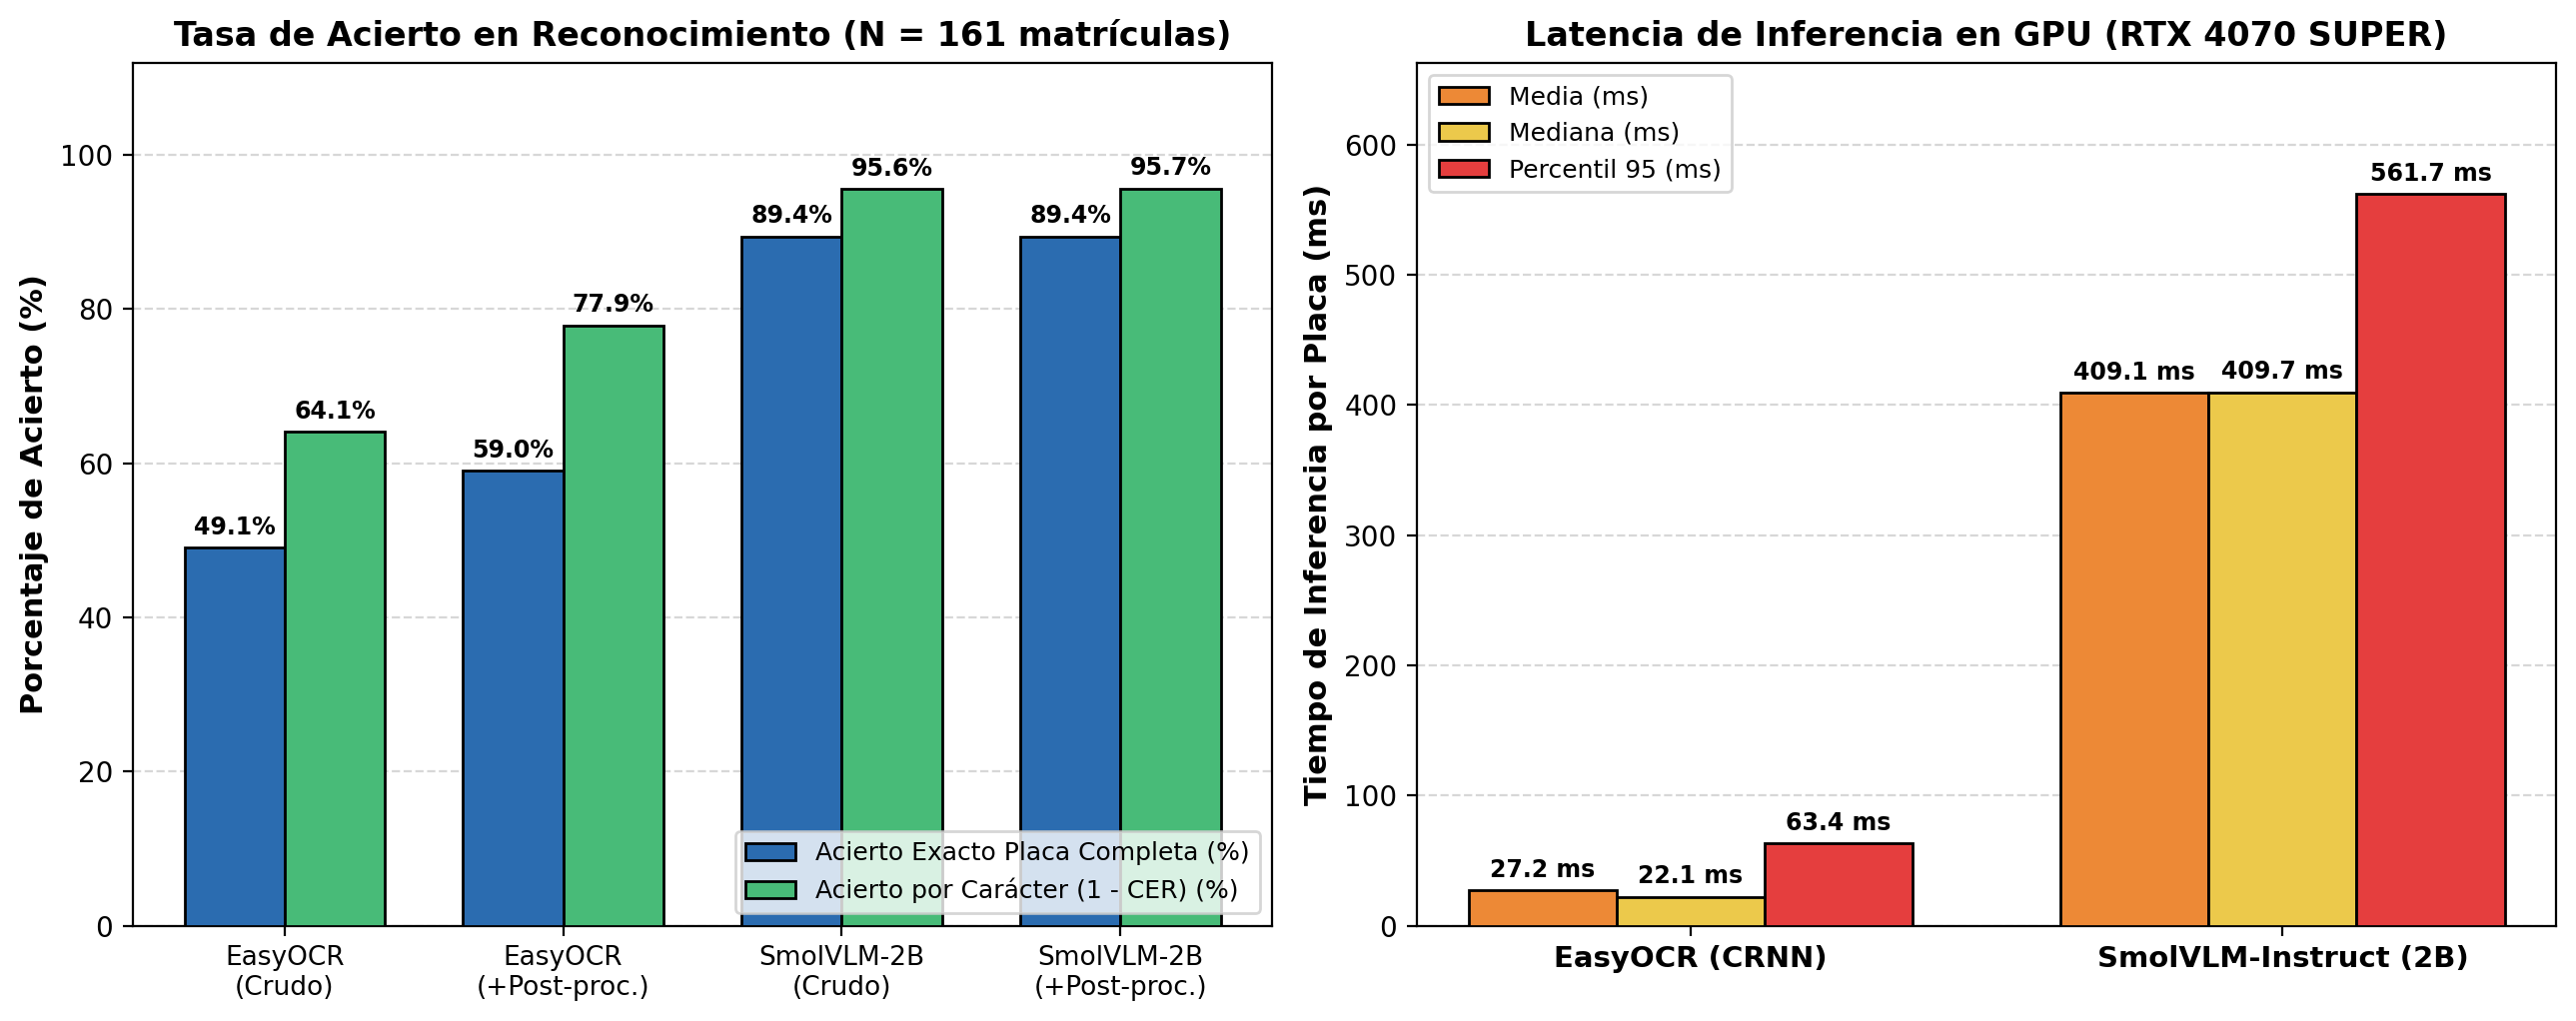

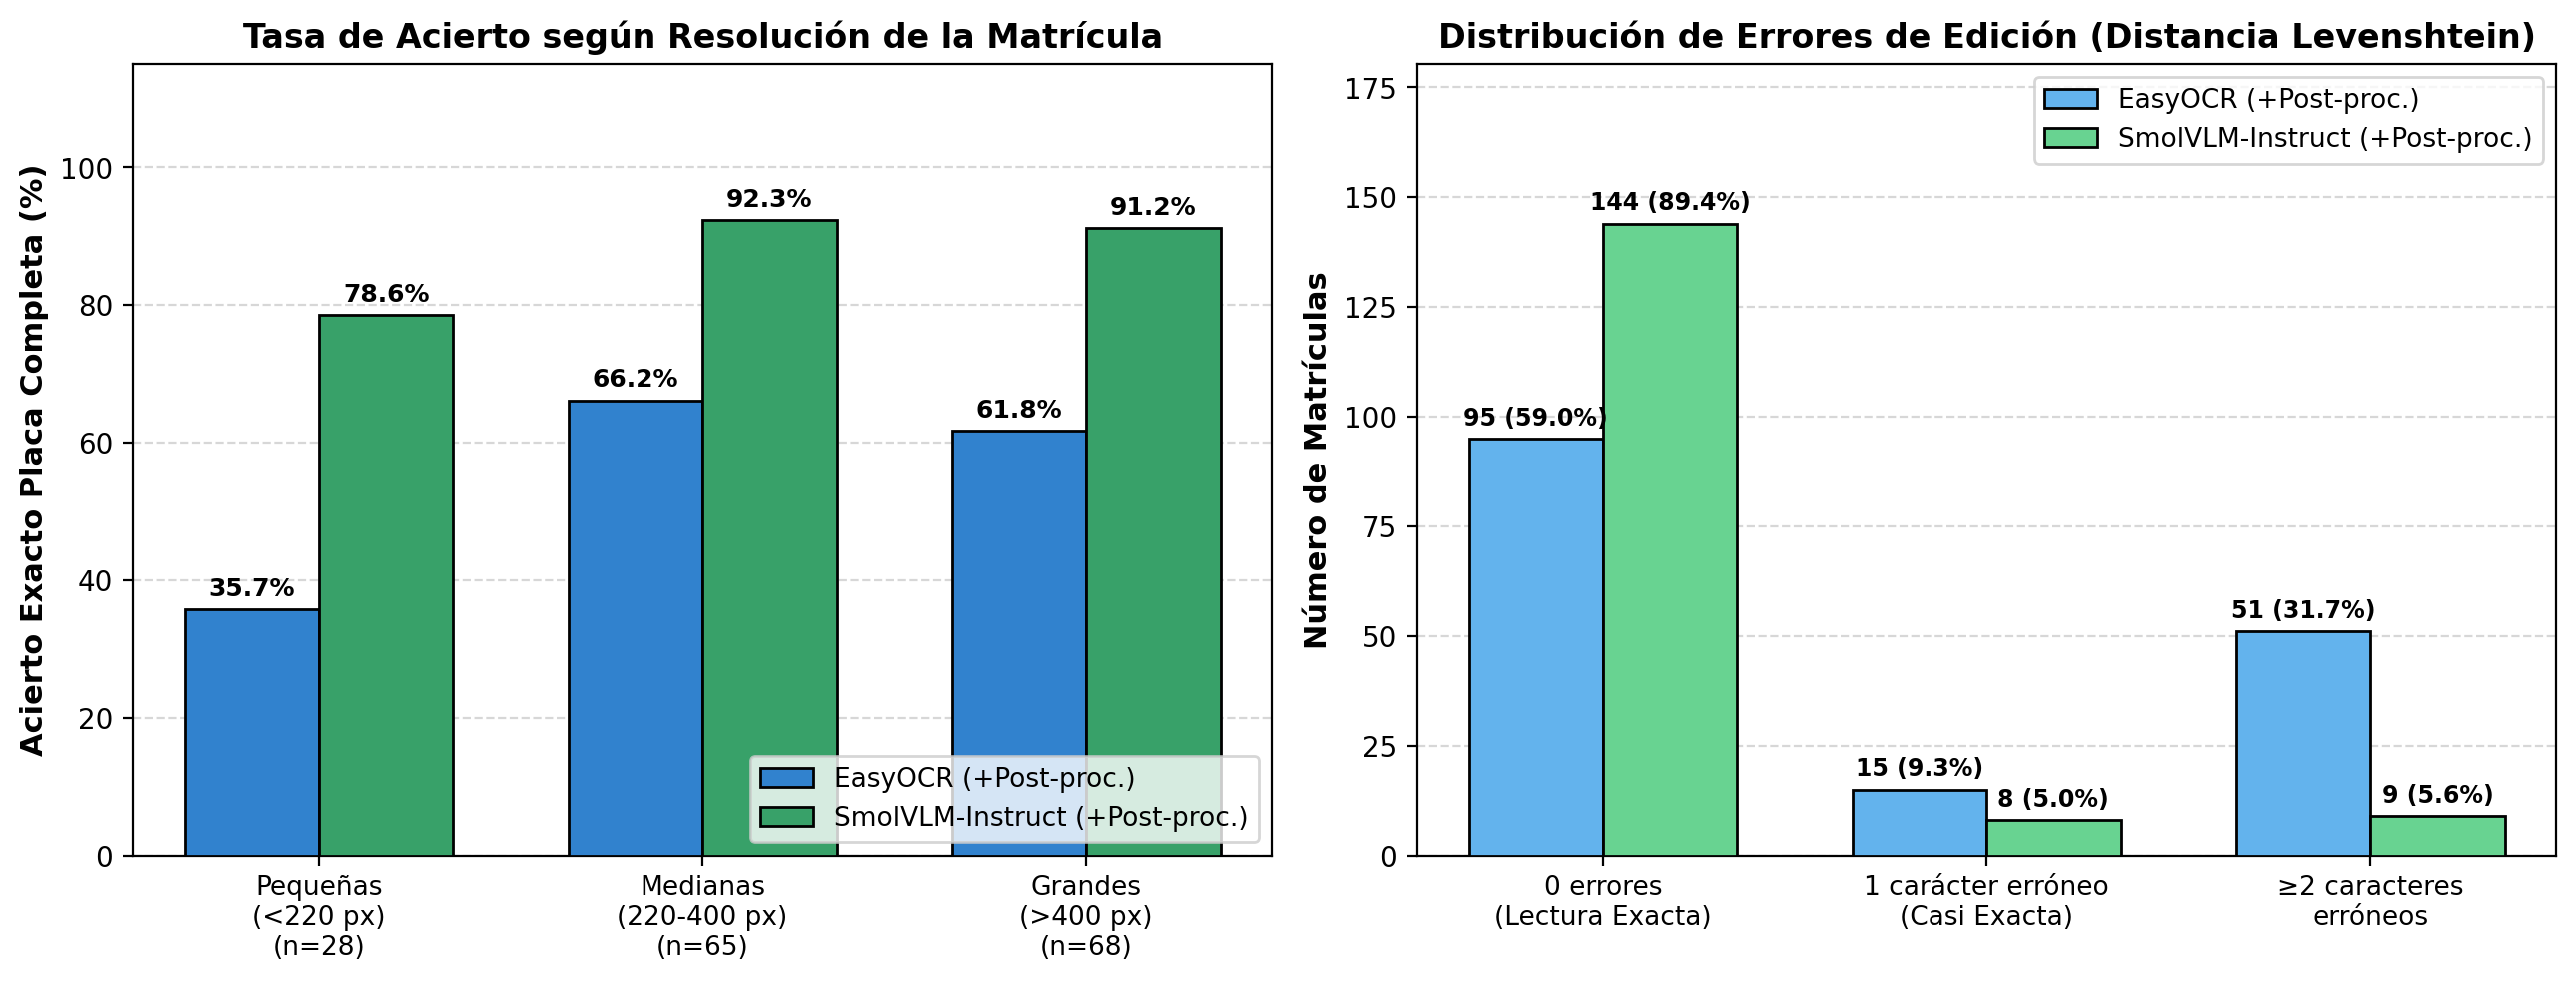

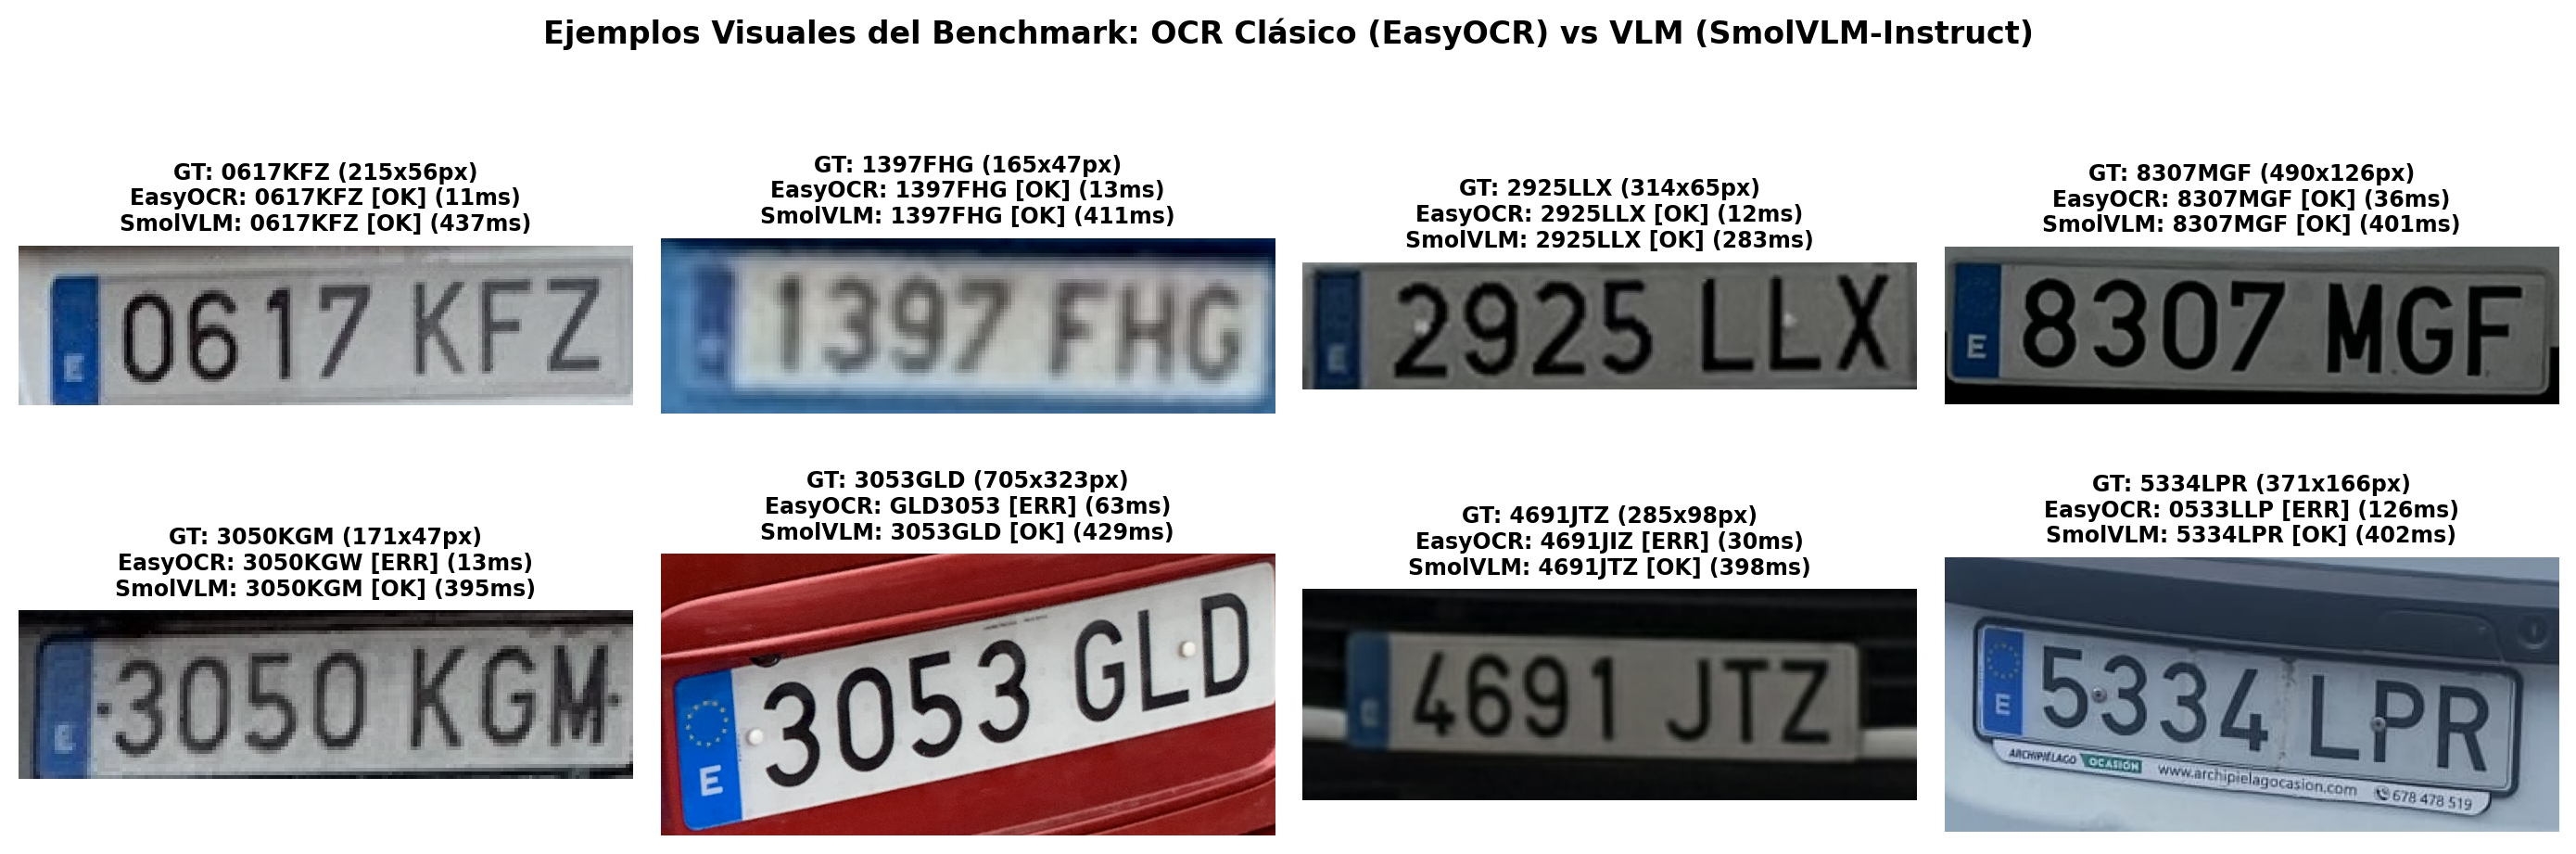

In [ ]:
import pandas as pd
from IPython.display import display, Image

df_gt = pd.read_csv("../P4b/ground_truth_matriculas.csv")
df_summary = pd.read_csv("../P4b/results/resumen_metricas_ocr.csv")
print(f"Total de matrículas evaluadas en el benchmark: {len(df_gt)}")
print(df_gt["source_type"].value_counts().to_string())
print("\n=== TABLA COMPARATIVA DE RENDIMIENTO Y TIEMPOS (RTX 4070 SUPER) ===")
print(df_summary.to_string(index=False))
display(Image("images/comparativa_ocr_rendimiento_tiempos.png"))
display(Image("images/comparativa_ocr_resolucion_errores.png"))
display(Image("images/ejemplos_comparativa_ocr.png"))

### 2. Integración del Reconocimiento OCR en el Vídeo (`C0142.MP4`) y Volcado al CSV (`results/resultado_C0142_detecciones.csv`)
Se ha expandido `TrafficAnalyzer` (`src/traffic_pipeline.py`) con el filtro de movimiento (`VehicleMotionFilter`) y la clase `PlateOCR` (`fast-plate-ocr` → `EasyOCR` → `SmolVLM-Instruct` con consenso multiframe y post-procesado español) para adquirir el texto de cada matrícula visible a lo largo del seguimiento persistente con **BoT-SORT**, mostrándolo en el vídeo de salida (`results/resultado_C0142_tracking.mp4`) y guardándolo en la columna `texto_matricula` del CSV oficial de 15 columnas.

El modo híbrido está disponible como opción en el Paso 6.


In [ ]:
df_det = pd.read_csv("results/resultado_C0142_detecciones.csv")
plates_si = df_det[df_det["matrícula_en_su_caso"] == "Si"]
plates_ocr = plates_si[plates_si["texto_matricula"].notna()]
print(f"Total de registros en el CSV: {len(df_det)}")
print(f"Total de vehículos con matrícula detectada: {len(plates_si)}")
print(f"Total de matrículas visibles con texto reconocido por OCR: {len(plates_ocr)}")
print("\n=== MATRÍCULAS RECONOCIDAS Y VOLCADAS EN EL CSV OFICIAL ===")
print(plates_ocr[["fotograma", "tipo_objeto", "identificador_tracking", "confianza.1", "mx1", "my1", "mx2", "my2", "texto_matricula"]].to_string(index=False))
display(Image("images/resultado_tracking_ocr_hud.jpg"))